<a href="https://colab.research.google.com/github/Tommys-laboratory1210/spatial-analysis-study/blob/main/lesson04/lesson_04_spatial_autocorrelation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
data = np.array([
    [10, 12, 11,  2,  3],
    [13, 15, 14,  4,  2],
    [11, 12, 13,  3,  4],
    [ 2,  3,  4, 14, 15],
    [ 3,  2,  4, 13, 12]
]) # 25 areas, each value means earthquake frequency

print(data)

[[10 12 11  2  3]
 [13 15 14  4  2]
 [11 12 13  3  4]
 [ 2  3  4 14 15]
 [ 3  2  4 13 12]]


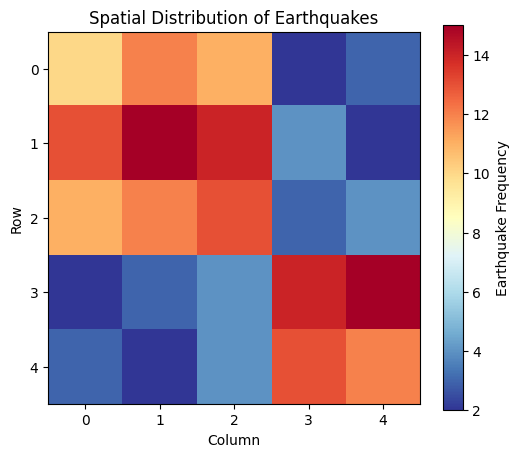

In [7]:
plt.figure(figsize = (6,5))
plt.imshow(data, cmap = "RdYlBu_r")
plt.colorbar(label="Earthquake Frequency")
plt.title("Spatial Distribution of Earthquakes")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show() # visualize spatial distribution

In [8]:
x = data.flatten() # flatten for Moran's I calculation

print(x)
print("Number of observations", len(x))

[10 12 11  2  3 13 15 14  4  2 11 12 13  3  4  2  3  4 14 15  3  2  4 13
 12]
NUmber of observations 25


In [12]:
n = data.shape[0]
W = np.zeros((n*n, n*n))

for r in range(n):
    for c in range(n):

        i = r*n + c

        neighbors = [
            (r-1, c),  # up
            (r+1, c),  # down
            (r, c-1),  # left
            (r, c+1)   # right
        ]

        for nr, nc in neighbors: # nr(neighbor row)

            if 0 <= nr < n and 0 <= nc < n:

                j = nr*n + nc
                W[i, j] = 1 # area i and j are neighborhood

print(W)

[[0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0.

In [13]:
print(W[12]) # neighbors' index j are 7, 11, 13, 17

[0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.
 0.]


In [14]:
print(np.where(W[12] == 1))

(array([ 7, 11, 13, 17]),)


In [16]:
neighbor_count = W.sum(axis=1)
print(neighbor_count)

[2. 3. 3. 3. 2. 3. 4. 4. 4. 3. 3. 4. 4. 4. 3. 3. 4. 4. 4. 3. 2. 3. 3. 3.
 2.]


In [17]:
print(neighbor_count.reshape(5, 5))

[[2. 3. 3. 3. 2.]
 [3. 4. 4. 4. 3.]
 [3. 4. 4. 4. 3.]
 [3. 4. 4. 4. 3.]
 [2. 3. 3. 3. 2.]]


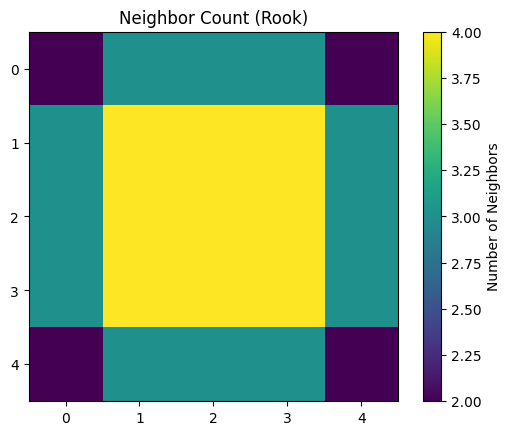

In [18]:
neighbor_grid = neighbor_count.reshape(5, 5)

plt.imshow(neighbor_grid, cmap="viridis")
plt.colorbar(label="Number of Neighbors")
plt.title("Neighbor Count (Rook)")
plt.show()

In [19]:
n = data.shape[0]
W = np.zeros((n*n, n*n))

for r in range(n):
    for c in range(n):

        i = r*n + c

        neighbors = [
    (r-1, c),    # up
    (r+1, c),    # down
    (r, c-1),    # left
    (r, c+1),    # right
    (r-1, c-1),  # upper-left
    (r-1, c+1),  # upper-right
    (r+1, c-1),  # lower-left
    (r+1, c+1)   # lower-right
] # queen

        for nr, nc in neighbors: # nr(neighbor row)

            if 0 <= nr < n and 0 <= nc < n:

                j = nr*n + nc
                W[i, j] = 1 # area i and j are neighborhood

print(W)

[[0. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [1. 0. 1. 0. 0. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 1. 0. 1. 0. 0. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 1. 0. 1. 0. 0. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [1. 1. 0. 0. 0. 0. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [1. 1. 1. 0. 0. 1. 0. 1. 0. 0. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 1. 1. 1. 0. 0. 1. 0. 1. 0. 0. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 1. 1. 1. 0. 0. 1. 0. 1. 0. 0. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 1. 1. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 0. 0. 1. 1. 1. 0. 0. 1. 0. 1. 0. 0. 1. 1. 1. 0. 0. 0. 0. 0. 0.
  0.]
 [0. 0. 0. 0. 0. 0. 1. 1. 1. 0. 0. 1. 0.

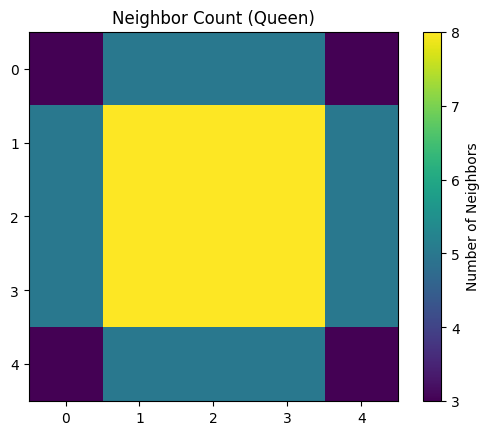

In [21]:
neighbor_count = W.sum(axis=1)
neighbor_grid = neighbor_count.reshape(5,5)

plt.imshow(neighbor_grid, cmap="viridis")
plt.colorbar(label="Number of Neighbors")
plt.title("Neighbor Count (Queen)")
plt.show()

In [23]:
# Global Moran's I
x_bar = x.mean()
print(x_bar)

8.04


In [28]:
z = x - x_bar
numerator = np.sum(W * np.outer(z,z))
denominator = np.sum(z**2)

S0 = W.sum() # sum number of neighborhoods
N = len(x) # number of observations

I = (N / S0) * (numerator/denominator)

print("Moran's I:", I)

Moran's I: 0.3987432758300872


In [30]:
def calculate_moran(x, W):
    N = len(x)
    x_bar = x.mean()
    z = x - x_bar
    S0 = W.sum()

    numerator = np.sum(W * np.outer(z, z))
    denominator = np.sum(z**2)

    I = (N / S0) * (numerator / denominator)

    return I

In [32]:
observed_I = calculate_moran(x, W)

print("Observed Moran's I:", observed_I)

Observed Moran's I: 0.3987432758300872


In [35]:
np.random.seed(42)

n_permutations = 999
permutation_I = []

for _ in range(n_permutations):
    shuffled_x = np.random.permutation(x)
    I_random = calculate_moran(shuffled_x, W)
    permutation_I.append(I_random)

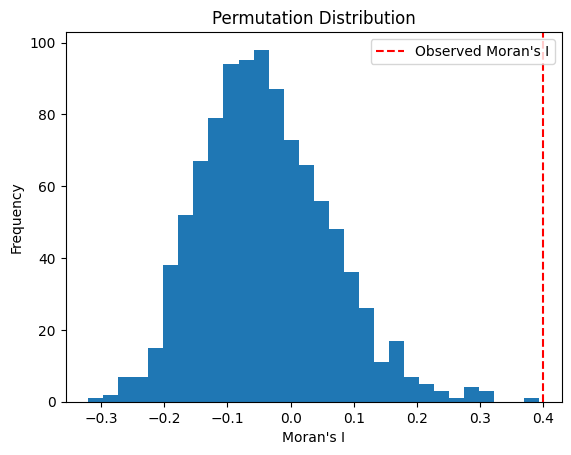

In [36]:
plt.hist(permutation_I, bins=30)
plt.axvline(observed_I, color="red", linestyle="--",
            label="Observed Moran's I")

plt.xlabel("Moran's I")
plt.ylabel("Frequency")
plt.title("Permutation Distribution")
plt.legend()
plt.show()

In [38]:
count = np.sum(np.array(permutation_I) >= observed_I)
p_value = (count + 1) / (n_permutations + 1)

print("Permutation p-value:", p_value)

Permutation p-value: 0.001
